In [2]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import smatch

Populating the interactive namespace from numpy and matplotlib


In [3]:
data=astTable.Table.read('wrkDir/s19/s19-1/problem/under-density-region.fits')

In [4]:
cat2=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/GAMA09H.fits')[0::10]

# GAMA09H 

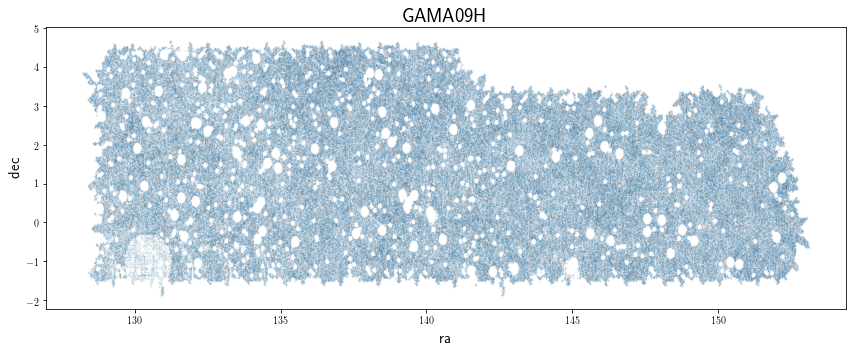

In [7]:
ra=cat2['i_ra']
dec=cat2['i_dec']
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

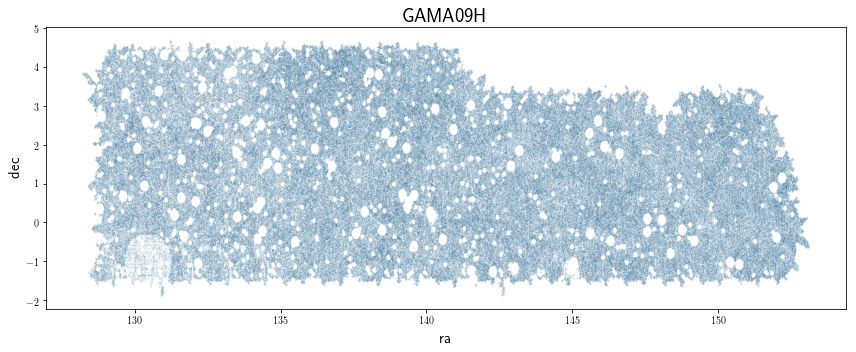

In [8]:
wlmask=utilities.update_wl_flags(cat2)['weak_lensing_flag']
ra=cat2[wlmask]['i_ra']
dec=cat2[wlmask]['i_dec']
fn='GAMA09H'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

![](http://member.ipmu.jp/xiangchong.li/G3Sim/low-dense-region/GAMA09H/tract-9314-patch-00_22-mask.png)

Tract 9314

'REJECTED' and 'UNMASKEDNAN'.

![](http://member.ipmu.jp/xiangchong.li/G3Sim/low-dense-region/GAMA09H/tract-9314-patch-00_22-img.png)

Tract 9314

![visit 0104934](http://member.ipmu.jp/xiangchong.li/G3Sim/low-dense-region/GAMA09H/visit-0104934-img.png)


![visit 0104934](http://member.ipmu.jp/xiangchong.li/G3Sim/low-dense-region/GAMA09H/visit-0104934-mask-bad-2080-big.png)

'NO_DATA' and 'CROSSTALK'



This should have indeed been removed from the visit list.  Comment to that visit:

>     Something wrong for tracking. Need retake => visit=104994 yasuda@stars

I think this suggests that we need an automated and robust mechanism to identify
bad visits.  A lesson for PFS.

Just in case you did not know, there is a public version of the HSC obslog:

https://hscobslog.naoj.org/obslog/session/new

-Masayuki 

# XMM

In [9]:
cat2=pyfits.getdata('wrkDir/database/s19-Hironao-2/fields/XMM.fits')[0::8]

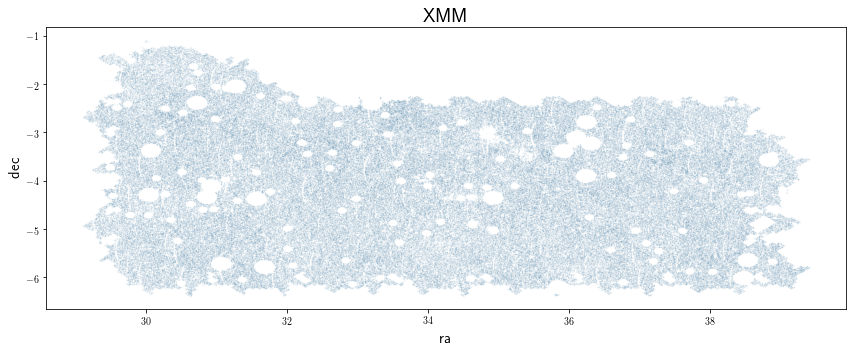

In [11]:
ra=cat2['i_ra']
dec=cat2['i_dec']
fn='XMM'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(ra,dec,s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [ ]:
mask=(data['tract']==8280)
mask&=(data['patch']==207)
wlmask=utilities.update_wl_flags(data)['weak_lensing_flag']

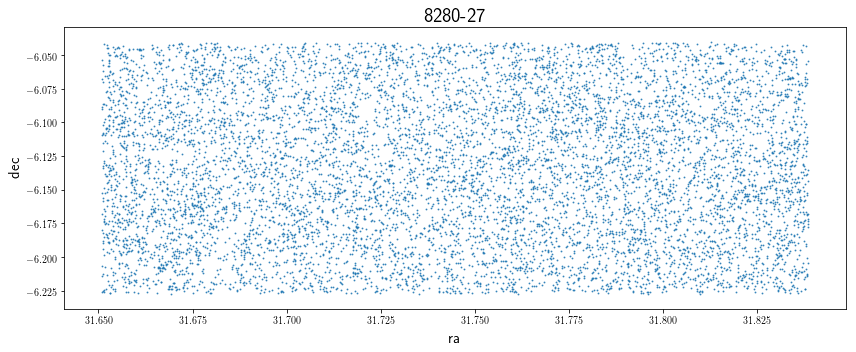

In [37]:
dataX=data[mask]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='8280-27'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

In [1]:
dataX=data[mask&wlmask]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='tract 8280, wl mask'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

NameError: name 'data' is not defined

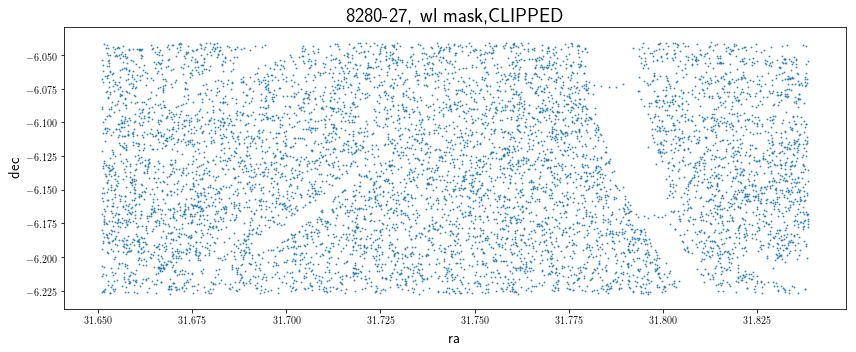

In [52]:
maskN=(~dataX['i_pixelflags_clipped'])
dataX=dataX[maskN]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='8280-27, wl mask,CLIPPED'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

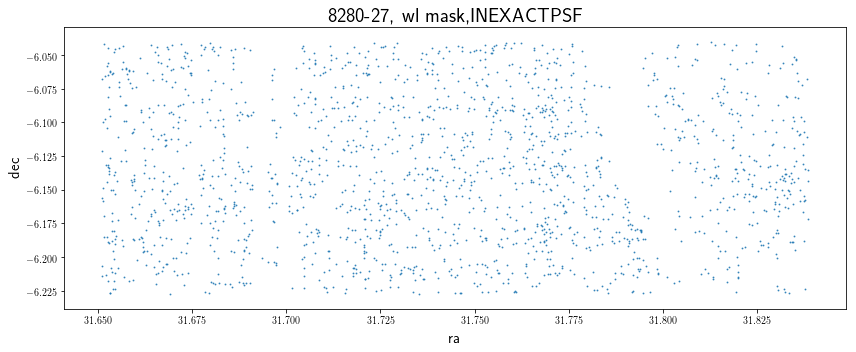

In [36]:
maskN=(~data['i_pixelflags_inexact_psf'])
dataX=data[maskN&mask&wlmask]
raX=dataX['i_ra']
decX=dataX['i_dec']
fn='8280-27, wl mask,INEXACTPSF'
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fn,fontsize=20)
plt.scatter(raX,decX,s=0.8,alpha=.8)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

```sql
NOT meas.i_deblend_skipped                  AND
 -- NOT meas.i_cmodel_flag_badcentroid      AND # This flag was not included in S16A, but if we find anything wrong, we can get it back.
 NOT meas2.i_sdsscentroid_flag          AND
 NOT meas.i_pixelflags_edge                 AND
 NOT meas.i_pixelflags_interpolatedcenter  AND
 NOT meas.i_pixelflags_saturatedcenter     AND
 NOT meas.i_pixelflags_crcenter            AND
 NOT meas.i_pixelflags_bad                  AND
 NOT meas.i_pixelflags_suspectcenter       AND
 NOT meas.i_pixelflags_clipped          AND
 meas.i_detect_isprimary                     AND
 NOT meas2.i_hsmshaperegauss_flag            AND 
```